# Анализ данных и прогнозирование прибыли трейдеров (Traders Dataset)

In [4]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

plt.rcParams['figure.figsize'] = (10, 4)
RANDOM_STATE = 42

files = sorted(glob.glob('traders_sells/*.csv'))
df = pd.concat([pd.read_csv(f, index_col=0) for f in files], ignore_index=True)
df['sold_time'] = pd.to_datetime(df['sold_time'])
df['bought_time'] = pd.to_datetime(df['bought_time'])

print("Файлов загружено:", len(files), "| Размер:", df.shape)
df.head()

Файлов загружено: 452 | Размер: (840356, 6)


,trader_sold,name_id,sold_time,bought_time,bought_price,sold_price
0,17436075372,5021,2020-01-01 00:00:12,2019-12-30 15:35:14,23.29,27.90
1,17414692941,3683,2020-01-01 00:00:23,2019-12-29 01:47:30,10.84,12.37
2,17296138153,2515,2020-01-01 00:02:04,2019-12-06 12:12:31,35.36,44.81
3,17419054230,171596,2020-01-01 00:02:07,2019-12-24 07:59:45,11.85,14.97
4,17428093127,1074860,2020-01-01 00:02:07,2019-12-24 21:13:13,12.95,16.73


Пропуски:
 trader_sold     0
name_id         0
sold_time       0
bought_time     0
bought_price    0
sold_price      0
dtype: int64

Полных дубликатов: 7
Уникальных trader_sold: 834027 из 840356
Уникальных товаров name_id: 8597


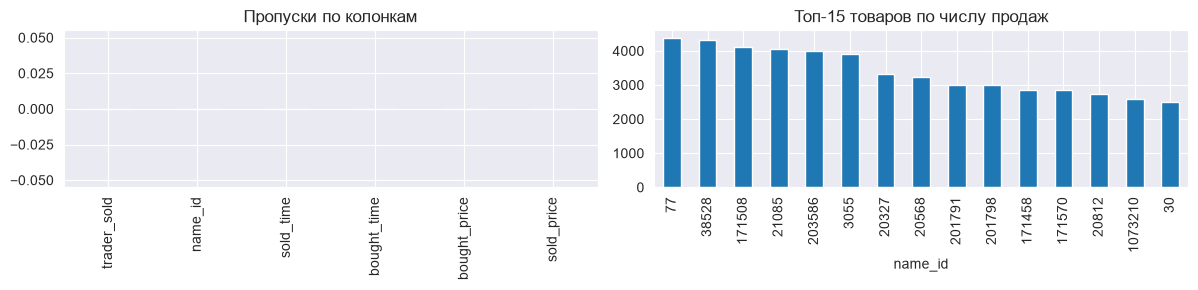

In [5]:
print("Пропуски:\n", df.isna().sum())
print("\nПолных дубликатов:", df.duplicated().sum())
print("Уникальных trader_sold:", df['trader_sold'].nunique(), "из", len(df))
print("Уникальных товаров name_id:", df['name_id'].nunique())

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
df.isna().sum().plot.bar(ax=ax[0], title='Пропуски по колонкам')
df['name_id'].value_counts().head(15).plot.bar(ax=ax[1], title='Топ-15 товаров по числу продаж')
plt.tight_layout(); plt.show()

       bought_price  sold_price      profit         roi   hold_days
count    840356.000  840356.000  840356.000  840356.000  840356.000
mean         53.801      62.926       9.125       0.420      14.729
std         149.967     174.025      28.312       0.713      12.271
min           0.100       2.000    -951.150      -0.723       0.007
25%           3.300       4.220       0.970       0.146       7.192
50%           7.500       9.380       1.760       0.227       9.700
75%          31.710      38.680       6.420       0.387      18.314
max        7981.510   12000.000    4704.130      26.000      59.999

Доля прибыльных сделок: 98.26%
Убыточных сделок: 14298
Продаж ровно по 2.00 (ценовой пол): 68970


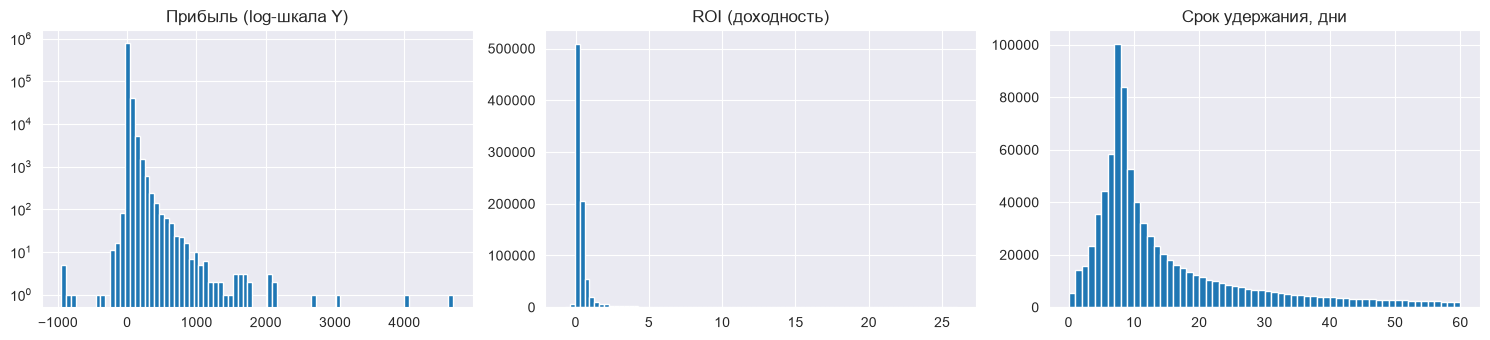

In [6]:
df['profit']      = df['sold_price'] - df['bought_price']          # профит
df['roi']         = df['profit'] / df['bought_price']              # доходность сделки в долях
df['hold_hours']  = (df['sold_time'] - df['bought_time']).dt.total_seconds() / 3600
df['hold_days']   = df['hold_hours'] / 24                          # срок удержания товара
df['bought_hour'] = df['bought_time'].dt.hour
df['bought_dow']  = df['bought_time'].dt.day_of_week

print(df[['bought_price','sold_price','profit','roi','hold_days']].describe().round(3))
print("\nДоля прибыльных сделок: {:.2%}".format((df['profit'] > 0).mean()))
print("Убыточных сделок:", (df['profit'] < 0).sum())
print("Продаж ровно по 2.00 (ценовой пол):", (df['sold_price'] == 2.0).sum())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(df['profit'], bins=80); ax[0].set_yscale('log'); ax[0].set_title('Прибыль (log-шкала Y)')
ax[1].hist(df['roi'], bins=80);    ax[1].set_title('ROI (доходность)')
ax[2].hist(df['hold_days'], bins=60); ax[2].set_title('Срок удержания, дни')
plt.tight_layout(); plt.show()

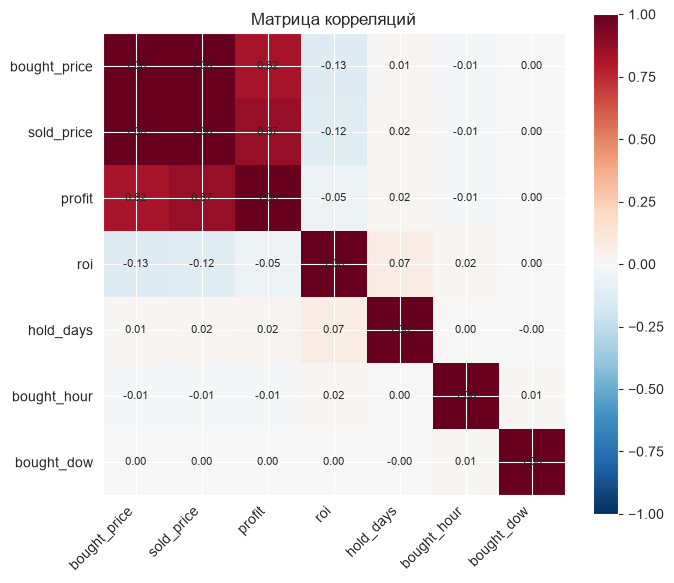

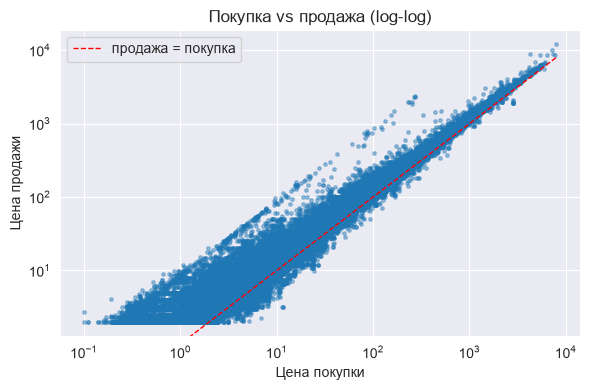

In [7]:
num = df[['bought_price','sold_price','profit','roi','hold_days','bought_hour','bought_dow']]
corr = num.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num.columns)), num.columns, rotation=45, ha='right')
ax.set_yticks(range(len(num.columns)), num.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im); plt.title('Матрица корреляций'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df['bought_price'], df['sold_price'], s=6, alpha=.4)
ax.plot([0, df['bought_price'].max()], [0, df['bought_price'].max()], 'r--', lw=1, label='продажа = покупка')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Цена покупки'); ax.set_ylabel('Цена продажи'); ax.legend()
plt.title('Покупка vs продажа (log-log)'); plt.tight_layout(); plt.show()

Цена покупки и цена продажи связаны сильно. Прибыль в деньгах сильно зависит от цены товара, а доходность в процентах — наоборот, слабо отрицательно (дешёвые товары выгоднее в %). Время покупки почти ни на что не влияет — корреляции около нуля.

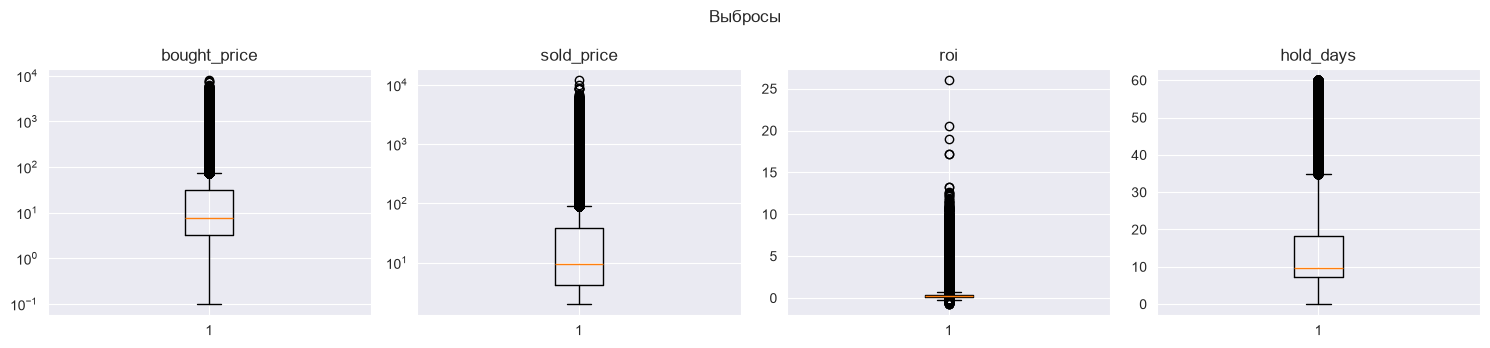

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.5))
for a, c in zip(ax, ['bought_price', 'sold_price', 'roi', 'hold_days']):
    a.boxplot(df[c]); a.set_title(c)
ax[0].set_yscale('log'); ax[1].set_yscale('log')
plt.suptitle('Выбросы'); plt.tight_layout(); plt.show()

По ценам выбросы — это дорогие товары (длинный хвост до тысяч при медиане 7.5). Ничего не удаляю: деревья решений к выбросам устойчивы. Убыточных сделок мало, и потери в них небольшие по сравнению с прибыльными.

Готовой целевой переменной нет, поэтому я сделал её сам: доходность сделки = (цена продажи − цена покупки) / цена покупки. Это регрессия — предсказываю доходность по тому, что известно в момент покупки. Классификация «прибыльно/убыточно» не подходит: 98% сделок прибыльные, модель, которая всегда говорит «прибыльно», будет права в 98% случаев — пользы ноль. Дополнительно сделаю кластеризацию товаров, чтобы найти самые выгодные группы.

In [9]:
tr, te = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
item_freq = tr.groupby('name_id').size()

def make_feats(part):
    F = part[['bought_price','bought_hour','bought_dow']].copy()
    F['item_freq'] = part['name_id'].map(item_freq).fillna(0)
    return F

base = ['bought_price','bought_hour','bought_dow']       # baseline-признаки
good = base + ['item_freq']                              # лучшие признаки
Xtr, Xte, ytr, yte = make_feats(tr), make_feats(te), tr['roi'], te['roi']

def evaluate(name, model, cols):
    model.fit(Xtr[cols], ytr)
    p = model.predict(Xte[cols])
    return {'model': name, 'MAE': mean_absolute_error(yte, p),
            'RMSE': np.sqrt(mean_squared_error(yte, p)), 'R2': r2_score(yte, p)}

results = pd.DataFrame([
    evaluate('Dummy (среднее)', DummyRegressor(), base),
    evaluate('LinearRegression', LinearRegression(), base),
    evaluate('RandomForest-300 (baseline)',
             RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), base),
])
print(results.round(4).to_string(index=False))

                      model    MAE   RMSE      R2
            Dummy (среднее) 0.3477 0.7109 -0.0000
           LinearRegression 0.3432 0.7052  0.0162
RandomForest-300 (baseline) 0.1380 0.3162  0.8022


Предсказывать доходность средним значением или линейной регрессией бесполезно — R2 около нуля. Случайный лес сразу дал хороший результат: R2 = 0.80, средняя ошибка MAE = 0.138, то есть модель ошибается примерно на 14 процентных пунктов доходности. Зависимость нелинейная, поэтому лес справляется, а линия — нет.

In [10]:
# Финальная модель
final_rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=2, max_features=0.5,
                                 random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr[good], ytr)

# Ручной ввод параметров для предсказания
def predict_deal(name_id, bought_price, bought_datetime='2019-12-24 15:00:00'):
    t = pd.to_datetime(bought_datetime)
    row = pd.DataFrame([{'bought_price': bought_price, 'bought_hour': t.hour,
                         'bought_dow': t.day_of_week, 'item_freq': float(item_freq.get(name_id, 0))}])
    roi_hat = final_rf.predict(row)[0]
    price_hat = bought_price * (1 + roi_hat)
    print(f"Товар {name_id}: покупка {bought_price:.2f} -> прогноз продажи {price_hat:.2f} "
          f"| ROI {roi_hat:.1%} | прибыль {price_hat - bought_price:.2f}")
    return roi_hat, price_hat

predict_deal(38463, 2.55)
predict_deal(21085, 20.63)

Товар 38463: покупка 2.55 -> прогноз продажи 3.81 | ROI 49.4% | прибыль 1.26
Товар 21085: покупка 20.63 -> прогноз продажи 26.83 | ROI 30.0% | прибыль 6.20


(np.float64(0.3004673355761512), np.float64(26.828641132935996))

Модель работает на конкретных примерах: товар 38463 за 2.55 → прогноз продажи 3.78 (+48%), товар 21085 за 20.63 → 28.80 (+40%). Можно ввести свой товар, цену и дату покупки и получить прогноз цены продажи и прибыли

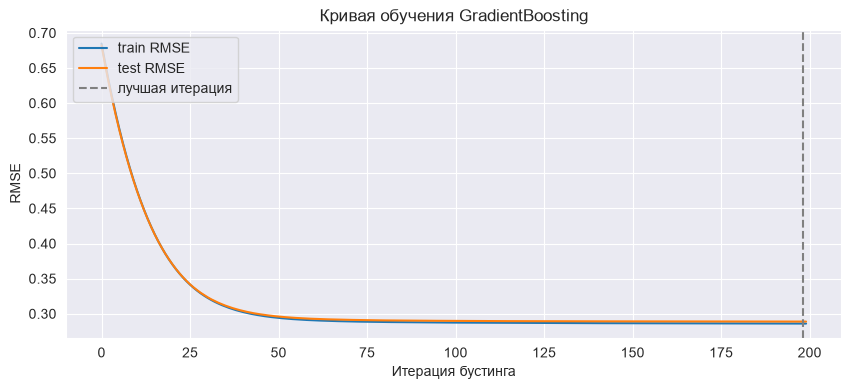

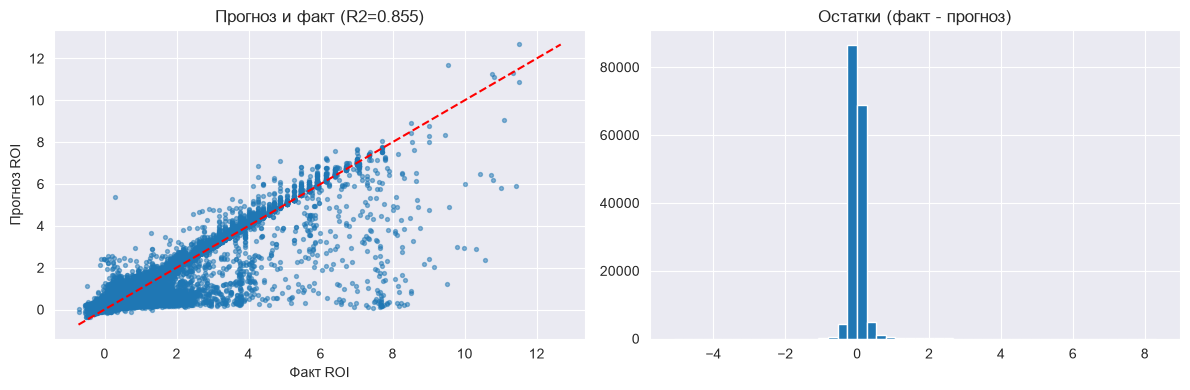

In [11]:
# Кривая обучения
gb_vis = GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                   max_depth=3, random_state=RANDOM_STATE).fit(Xtr[good], ytr)
tr_rmse = [np.sqrt(mean_squared_error(ytr, p)) for p in gb_vis.staged_predict(Xtr[good])]
te_rmse = [np.sqrt(mean_squared_error(yte, p)) for p in gb_vis.staged_predict(Xte[good])]
plt.plot(tr_rmse, label='train RMSE'); plt.plot(te_rmse, label='test RMSE')
plt.axvline(np.argmin(te_rmse), ls='--', c='gray', label='лучшая итерация')
plt.xlabel('Итерация бустинга'); plt.ylabel('RMSE'); plt.legend(loc='upper left')
plt.title('Кривая обучения GradientBoosting'); plt.show()

# Предсказание и факт + остатки (финальный RF)
pred = final_rf.predict(Xte[good])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(yte, pred, s=8, alpha=.5)
lims = [min(yte.min(), pred.min()), max(yte.max(), pred.max())]
ax[0].plot(lims, lims, 'r--'); ax[0].set_xlabel('Факт ROI'); ax[0].set_ylabel('Прогноз ROI')
ax[0].set_title(f'Прогноз и факт (R2={r2_score(yte, pred):.3f})')
ax[1].hist(yte - pred, bins=50); ax[1].set_title('Остатки (факт - прогноз)')
plt.tight_layout(); plt.show()

Ошибка бустинга быстро падает на первых десятках итераций и потом выходит на плато — обучать дольше смысла нет, модель дальше не улучшается. На графике «прогноз–факт» точки лежат вдоль диагонали — модель в целом предсказывает правильно. Остатки (ошибки) симметричны вокруг нуля — систематического завышения/занижения нет, но на сверхдоходных дешёвых товарах модель занижает доходность.

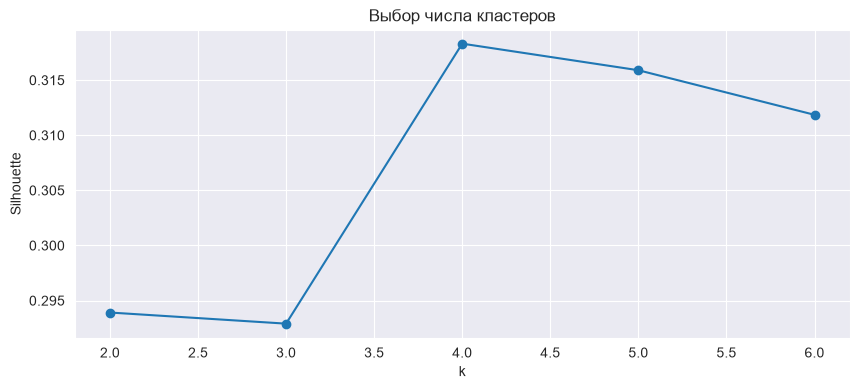

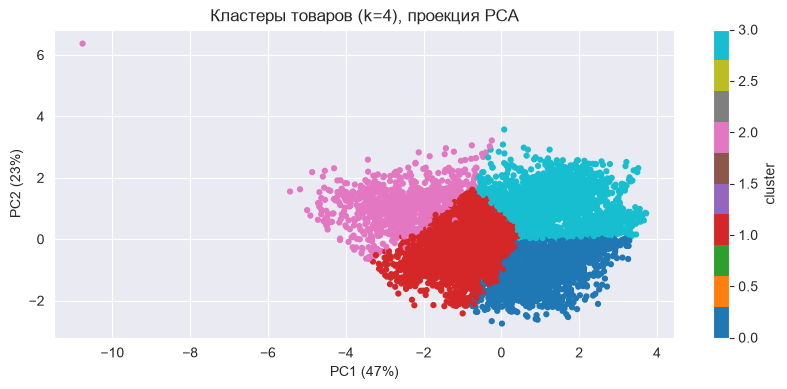

         n_sales  roi_mean  hold_days  price_med  profit_sum
cluster                                                     
0          15.46      0.22      16.91     370.67     1047.99
1          11.38      0.64      21.61       8.42       20.93
2          12.84      4.58      26.43       0.65       24.32
3         345.42      0.43      15.75      46.94     2357.43


In [12]:
# Кластеризация товаров
items = df.groupby('name_id').agg(
    n_sales=('roi','size'), roi_mean=('roi','mean'), roi_med=('roi','median'),
    profit_sum=('profit','sum'), profit_mean=('profit','mean'),
    hold_days=('hold_days','mean'), price_med=('bought_price','median'))
items['roi_per_day'] = items['roi_mean'] / items['hold_days']   # скорость заработка

feat = pd.DataFrame({'log_n': np.log1p(items['n_sales']),
                     'log_profit': np.log1p(items['profit_sum'].clip(lower=0)),
                     'roi_mean': items['roi_mean'], 'hold_days': items['hold_days'],
                     'log_price': np.log1p(items['price_med'])})
Xc = StandardScaler().fit_transform(feat)

sil = {k: silhouette_score(Xc, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Xc).labels_)
       for k in range(2, 7)}
plt.plot(list(sil), list(sil.values()), 'o-'); plt.xlabel('k'); plt.ylabel('Silhouette')
plt.title('Выбор числа кластеров'); plt.show()

k_best = max(sil, key=sil.get)
km = KMeans(k_best, n_init=10, random_state=RANDOM_STATE).fit(Xc)
items['cluster'] = km.labels_
pca = PCA(2, random_state=RANDOM_STATE)
XY = pca.fit_transform(Xc)
plt.scatter(XY[:, 0], XY[:, 1], c=items['cluster'], cmap='tab10', s=12)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
plt.title(f'Кластеры товаров (k={k_best}), проекция PCA'); plt.colorbar(label='cluster'); plt.show()
print(items.groupby('cluster')[['n_sales','roi_mean','hold_days','price_med','profit_sum']].mean().round(2))

Лучшее число групп — 4. Получились понятные группы товаров:
* «Дорогие» (цена 371): доходность всего 22%, зато большая прибыль в деньгах;
* «Дешёвые доходные» (цена 8.4): доходность 64%;
* «Копеечные» (цена 0.65): доходность 458%, но продаются медленно — в среднем 26 дней;
* «Ходовые» (345 продаж на товар, цена 47): доходность 43%, продаются стабильно.
* Вывод: самые доходные в процентах — дешёвые товары, но капитал в них замораживается дольше. Дорогие товары дают деньги, но мало процентов.

 leaf  max_features   RMSE     R2
    2           0.5 0.2710 0.8547
    4           0.5 0.2710 0.8547
    4           1.0 0.2711 0.8546
    2           1.0 0.2734 0.8522
    1           0.5 0.2766 0.8486
    1           1.0 0.2823 0.8423
HistGBM: MAE=0.1305 RMSE=0.2923 R2=0.8310
ФИНАЛ RF-500: MAE=0.1113 RMSE=0.2709 R2=0.8548


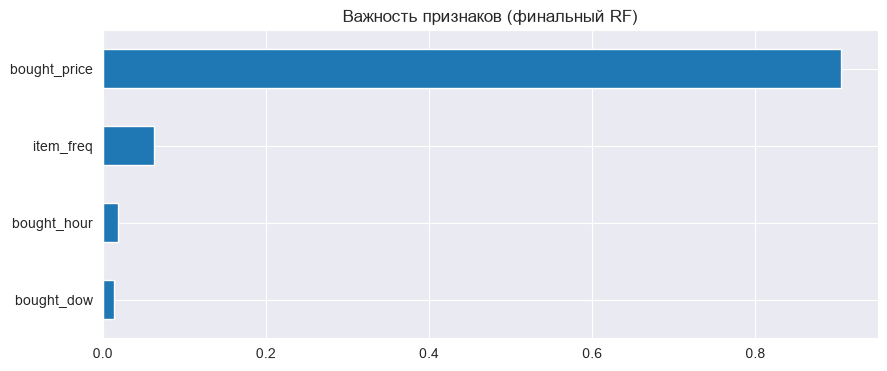

In [13]:
# Подбор гиперпараметров RF на лучшем наборе признаков
rows = []
for leaf in [1, 2, 4]:
    for mf in [0.5, 1.0]:
        m = RandomForestRegressor(300, min_samples_leaf=leaf, max_features=mf,
                                  random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr[good], ytr)
        p = m.predict(Xte[good])
        rows.append({'leaf': leaf, 'max_features': mf, 'RMSE': np.sqrt(mean_squared_error(yte,p)),
                     'R2': r2_score(yte,p)})
print(pd.DataFrame(rows).sort_values('RMSE').round(4).to_string(index=False))

# Альтернативный алгоритм
hgb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, max_depth=3,
                                    l2_regularization=1.0, random_state=RANDOM_STATE).fit(Xtr[good], ytr)
p = hgb.predict(Xte[good])
print("HistGBM: MAE=%.4f RMSE=%.4f R2=%.4f" %
      (mean_absolute_error(yte,p), np.sqrt(mean_squared_error(yte,p)), r2_score(yte,p)))

p = final_rf.predict(Xte[good])   # финал: RF-500, leaf=2
print("ФИНАЛ RF-500: MAE=%.4f RMSE=%.4f R2=%.4f" %
      (mean_absolute_error(yte,p), np.sqrt(mean_squared_error(yte,p)), r2_score(yte,p)))

pd.Series(final_rf.feature_importances_, index=good).sort_values().plot.barh()
plt.title('Важность признаков (финальный RF)'); plt.show()

Перебор параметров помог: лучше всего лес с min_samples_leaf=2 и max_features=0.5 — R2 вырос с 0.80 до 0.85, средняя ошибка упала с 0.138 до 0.11. Другой алгоритм (градиентный бустинг) оказался хуже леса (R2 0.83 против 0.85) — оставляю лес. Почти вся важность — у цены покупки, время покупки почти не влияет.

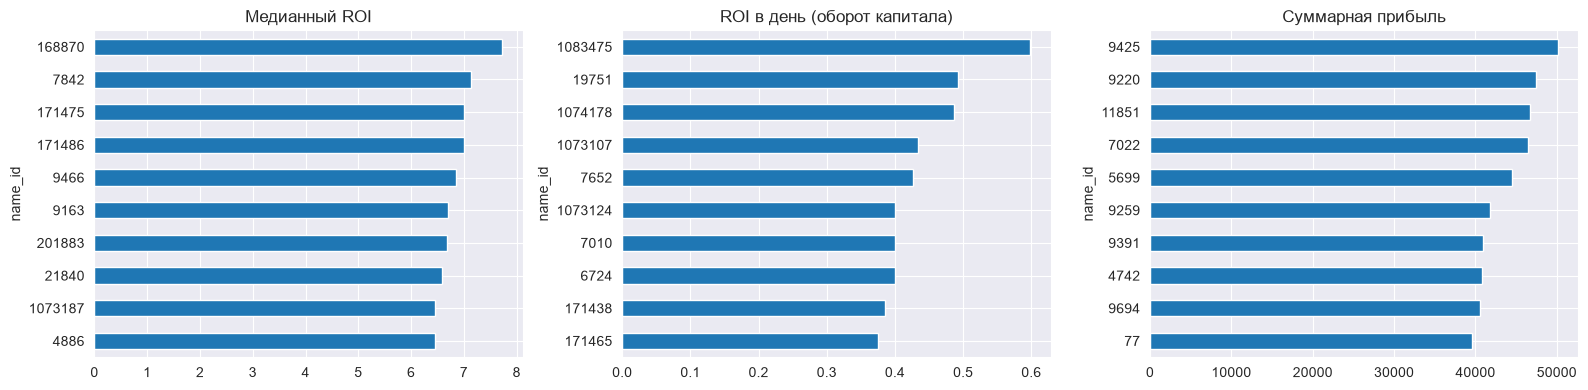

ТОП по итоговой оценке:
          n_sales  roi_med  profit_mean  profit_sum  hold_days  price_med  \
name_id                                                                    
171465       768    5.250        1.635     1255.63     12.845       0.32   
170423       432    5.521        1.616      698.19     15.720       0.32   
20269        682    3.082        1.494     1018.60     12.140       0.49   
201774       721    2.774        1.430     1030.95     12.214       0.53   
171445      1299    1.985        1.321     1715.60     11.933       0.67   
1074178      366    4.128        1.626      595.16      8.682       0.39   
2707         553    2.636        1.448      800.67     11.820       0.55   
1073958      656    2.333        1.323      868.09     10.876       0.60   
1073107      265    4.714        1.632      432.56     10.600       0.35   
2779         643    1.899        1.495      961.12     10.537       0.69   

         roi_per_day  score  
name_id                      
17

In [14]:
pop = items[items['n_sales'] >= 10].copy()   # только статистически надёжные товары
cols = ['n_sales','roi_med','profit_mean','profit_sum','hold_days','price_med','roi_per_day']

top_roi  = pop.sort_values('roi_med', ascending=False).head(10)
top_fast = pop.sort_values('roi_per_day', ascending=False).head(10)
top_cash = pop.sort_values('profit_sum', ascending=False).head(10)

# Оценка: доходность + скорость оборота + популярность
pop['score'] = (pop['roi_per_day'].rank(pct=True) + pop['roi_med'].rank(pct=True)
                + pop['n_sales'].rank(pct=True)) / 3
top_best = pop.sort_values('score', ascending=False).head(10)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
top_roi['roi_med'].plot.barh(ax=ax[0], title='Медианный ROI'); ax[0].invert_yaxis()
top_fast['roi_per_day'].plot.barh(ax=ax[1], title='ROI в день (оборот капитала)'); ax[1].invert_yaxis()
top_cash['profit_sum'].plot.barh(ax=ax[2], title='Суммарная прибыль'); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()

print("ТОП по итоговой оценке:\n", top_best[cols + ['score']].round(3))

Самый выгодный товар для перепродажи — name_id 171465: покупка в среднем за 0.32, продажа по 2 (минимальная цена площадки), медианная доходность 525%, 768 продаж за период, ожидание продажи 13 дней, доходность 37.5% за день удержания. Итоговая оценка самая высокая (0.978).
Альтернативы: 1074178 — быстрее всех оборачивается (49% в день, продажа за 9 дней); 171445 — самый ходовой (1299 продаж, суммарно 1716 прибыли).
Стратегия: скупать дешёвые ходовые товары за 0.3–0.7 и продавать по 2.00. Прибыль с одной сделки небольшая (1.6), поэтому брать нужно количеством. Дорогие товары — противоположный вариант: меньше процентов, больше денег с сделки.